# Simulasi Deep Neural Network (DNN) 2 Hidden Layers from Scratch
## Subkasus 1: Pemetaan Skalar $\mathbb{R}^3 \to \mathbb{R}^1$
### **Variasi 3 (Skalar): Inisialisasi Berbeda-beda, Aktivasi Sigmoid**

Dokumen ini memuat implementasi *from scratch* komputasi matriks *forward pass* ($H^{(\ell)} = X^{(\ell-1)} W^{(\ell)} + \mathbf{1}_N \mathbf{b}^{(\ell)}$, $X^{(\ell)} = f(H^{(\ell)})$), evaluasi MSE *loss*, dan *backward pass* dengan konfigurasi berikut:

* **Sifat Bobot**: **Skalar** (Deterministik)
* **Input Layer ($\ell = 0$)**: $n_0 = 3$ fitur
* **Hidden Layer 1 ($\ell = 1$)**: $n_1 = 4$ neuron, aktivasi Sigmoid
* **Hidden Layer 2 ($\ell = 2$)**: $n_2 = 6$ neuron, aktivasi Sigmoid
* **Output Layer ($\ell = 3$)**: $n_3 = 1$ neuron, aktivasi Linier
* **Banyak Data ($N$)**: $5$ sampel
* **Learning Rate ($\eta$)**: $0.5$
* **Total Iterasi**: $500$ iterasi
* **Random Seed**: $67$
* **Inisialisasi**: Parameter bernilai berbeda-beda / heterogen


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)

# 1. Kunci Random Seed
np.random.seed(67)

# 2. Matriks Data Input X in R^(5 x 3)
X = np.array([
    [0.1, 0.2, 0.3],
    [0.4, 0.1, 0.5],
    [0.2, 0.6, 0.1],
    [0.5, 0.3, 0.2],
    [0.3, 0.4, 0.4]
], dtype=np.float64)

# 3. Target Pemetaan R^3 -> R^1: y = 0.5*x1 - 0.3*x2 + 0.8*x3
Y = (0.5 * X[:, 0] - 0.3 * X[:, 1] + 0.8 * X[:, 2]).reshape(-1, 1)
N = X.shape[0]

# 4. Dimensi Jaringan
n0, n1, n2, n3 = 3, 4, 6, 1
lr = 0.5
num_epochs = 500

# 5. Fungsi Aktivasi Hidden Layer f(h) & Turunannya f'(h)
def activation(h):
    return 1.0 / (1.0 + np.exp(-h))

def activation_deriv(h):
    s = activation(h)
    return s * (1.0 - s)

# 6. Inisialisasi Parameter Bobot dan Bias
W1 = np.array([
    [ 0.1, -0.2,  0.3,  0.1],
    [-0.1,  0.3, -0.1,  0.2],
    [ 0.2,  0.1, -0.2, -0.3]
], dtype=np.float64)
b1 = np.array([[0.1, -0.1, 0.2, 0.0]], dtype=np.float64)

W2 = np.array([
    [ 0.2, -0.1,  0.3,  0.1, -0.2,  0.1],
    [-0.2,  0.2, -0.1,  0.3,  0.1, -0.1],
    [ 0.1, -0.3,  0.2, -0.1,  0.2,  0.3],
    [-0.1,  0.1, -0.2,  0.2, -0.1,  0.2]
], dtype=np.float64)
b2 = np.array([[0.1, 0.0, -0.1, 0.2, -0.2, 0.1]], dtype=np.float64)

W3 = np.array([
    [ 0.3],
    [-0.2],
    [ 0.4],
    [-0.1],
    [ 0.2],
    [-0.3]
], dtype=np.float64)
b3 = np.array([[0.1]], dtype=np.float64)
print("Data Input X (5 x 3):\n", X)
print("\nData Target Y (5 x 1):\n", Y)


Data Input X (5 x 3):
 [[0.1 0.2 0.3]
 [0.4 0.1 0.5]
 [0.2 0.6 0.1]
 [0.5 0.3 0.2]
 [0.3 0.4 0.4]]

Data Target Y (5 x 1):
 [[0.23]
 [0.57]
 [0.  ]
 [0.32]
 [0.35]]


In [2]:
# Loop Pelatihan (500 Iterasi)
history = []
milestones = [1, 2, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
predictions_history = {}

for epoch in range(1, num_epochs + 1):
    # --- FORWARD PASS (SKALAR) ---
    H1 = X @ W1 + b1
    X1 = activation(H1)
    
    H2 = X1 @ W2 + b2
    X2 = activation(H2)
    
    H3 = X2 @ W3 + b3
    Y_hat = H3
    
    # Evaluasi Loss: MSE = 1/(2N) * sum((Y - Y_hat)^2)
    loss = (0.5 / N) * np.sum((Y - Y_hat) ** 2)
    history.append((epoch, loss, Y_hat.copy()))
    if epoch in milestones:
        predictions_history[epoch] = Y_hat.copy()
        
    # --- BACKWARD PASS (SKALAR) ---
    # Layer 3 (l = 3)
    dL_dH3 = (1.0 / N) * (Y_hat - Y)             # (N x 1)
    dL_dW3 = X2.T @ dL_dH3                       # (6 x 1)
    dL_db3 = np.ones((1, N)) @ dL_dH3            # (1 x 1)
    
    # Layer 2 (l = 2, menggunakan dL_dH3 dan W3 dari layer l+1 = 3)
    dL_dX2 = dL_dH3 @ W3.T                       # (N x 6)
    dL_dH2 = dL_dX2 * activation_deriv(H2)       # (N x 6)
    dL_dW2 = X1.T @ dL_dH2                       # (4 x 6)
    dL_db2 = np.ones((1, N)) @ dL_dH2            # (1 x 6)
    
    # Layer 1 (l = 1, menggunakan dL_dH2 dan W2 dari layer l+1 = 2)
    dL_dX1 = dL_dH2 @ W2.T                       # (N x 4)
    dL_dH1 = dL_dX1 * activation_deriv(H1)       # (N x 4)
    dL_dW1 = X.T @ dL_dH1                        # (3 x 4)
    dL_db1 = np.ones((1, N)) @ dL_dH1            # (1 x 4)
    
    # --- UPDATE PARAMETER ---
    W3 -= lr * dL_dW3
    b3 -= lr * dL_db3
    W2 -= lr * dL_dW2
    b2 -= lr * dL_db2
    W1 -= lr * dL_dW1
    b1 -= lr * dL_db1
    
    if epoch in [1, 2]:
        print(f"================ DETAIL ITERASI KE-{epoch} ================")
        print("H^(1):\n", H1, "\nX^(1):\n", X1)
        print("H^(2):\n", H2, "\nX^(2):\n", X2)
        print(f"Y_hat: {Y_hat.ravel()} | Loss: {loss:.6f}")
        print("dL/dH^(3):", dL_dH3.ravel(), "| dL/dW^(3):", dL_dW3.ravel(), "| dL/db^(3):", dL_db3.ravel())
        print("dL/dX^(2):\n", dL_dX2, "\ndL/dH^(2):\n", dL_dH2)
        print("dL/dW^(2):\n", dL_dW2, "\ndL/db^(2):", dL_db2.ravel())
        print("dL/dX^(1):\n", dL_dX1, "\ndL/dH^(1):\n", dL_dH1)
        print("dL/dW^(1):\n", dL_dW1, "\ndL/db^(1):", dL_db1.ravel())
        print("Updated W^(3):", W3.ravel(), "| b^(3):", b3.ravel())
        print("Updated W^(2):\n", W2, "\nUpdated b^(2):", b2.ravel())
        print("Updated W^(1):\n", W1, "\nUpdated b^(1):", b1.ravel(), "\n")

# Tampilkan Rangkuman Nilai Tiap Kelipatan 50 Iterasi
print(f"{'Iterasi':<8} | {'MSE Loss':<12} | {'Rata-rata Prediksi':<20} | {'Prediksi y_hat [1..5]'}")
print("-" * 75)
for ep in milestones:
    _, ep_loss, ep_pred = history[ep - 1]
    pred_str = ", ".join([f"{val[0]:.4f}" for val in ep_pred])
    print(f"{ep:<8} | {ep_loss:<12.6f} | {np.mean(ep_pred):<20.4f} | [{pred_str}]")


================ DETAIL ITERASI KE-1 ================
H^(1):
 [[ 0.15 -0.03  0.15 -0.04]
 [ 0.23 -0.1   0.21 -0.09]
 [ 0.08  0.05  0.18  0.11]
 [ 0.16 -0.09  0.28  0.05]
 [ 0.17  0.    0.17 -0.01]] 
X^(1):
 [[0.5374 0.4925 0.5374 0.49  ]
 [0.5572 0.475  0.5523 0.4775]
 [0.52   0.5125 0.5449 0.5275]
 [0.5399 0.4775 0.5695 0.5125]
 [0.5424 0.5    0.5424 0.4975]]
H^(2):
 [[ 0.1137 -0.0675  0.0215  0.4458 -0.1998  0.3637]
 [ 0.1239 -0.0787  0.0346  0.4385 -0.2012  0.3694]
 [ 0.1032 -0.0602  0.0082  0.4568 -0.1965  0.3697]
 [ 0.1182 -0.0781  0.0256  0.4428 -0.1976  0.3796]
 [ 0.113  -0.0672  0.0217  0.4495 -0.1998  0.3665]] 
X^(2):
 [[0.5284 0.4831 0.5054 0.6096 0.4502 0.5899]
 [0.5309 0.4803 0.5087 0.6079 0.4499 0.5913]
 [0.5258 0.485  0.5021 0.6122 0.451  0.5914]
 [0.5295 0.4805 0.5064 0.6089 0.4508 0.5938]
 [0.5282 0.4832 0.5054 0.6105 0.4502 0.5906]]
Y_hat: [0.2161 0.2185 0.2131 0.2164 0.2158] | Loss: 0.019793
dL/dH^(3): [-0.0028 -0.0703  0.0426 -0.0207 -0.0268] | dL/dW^(3): [-0.0415 -0

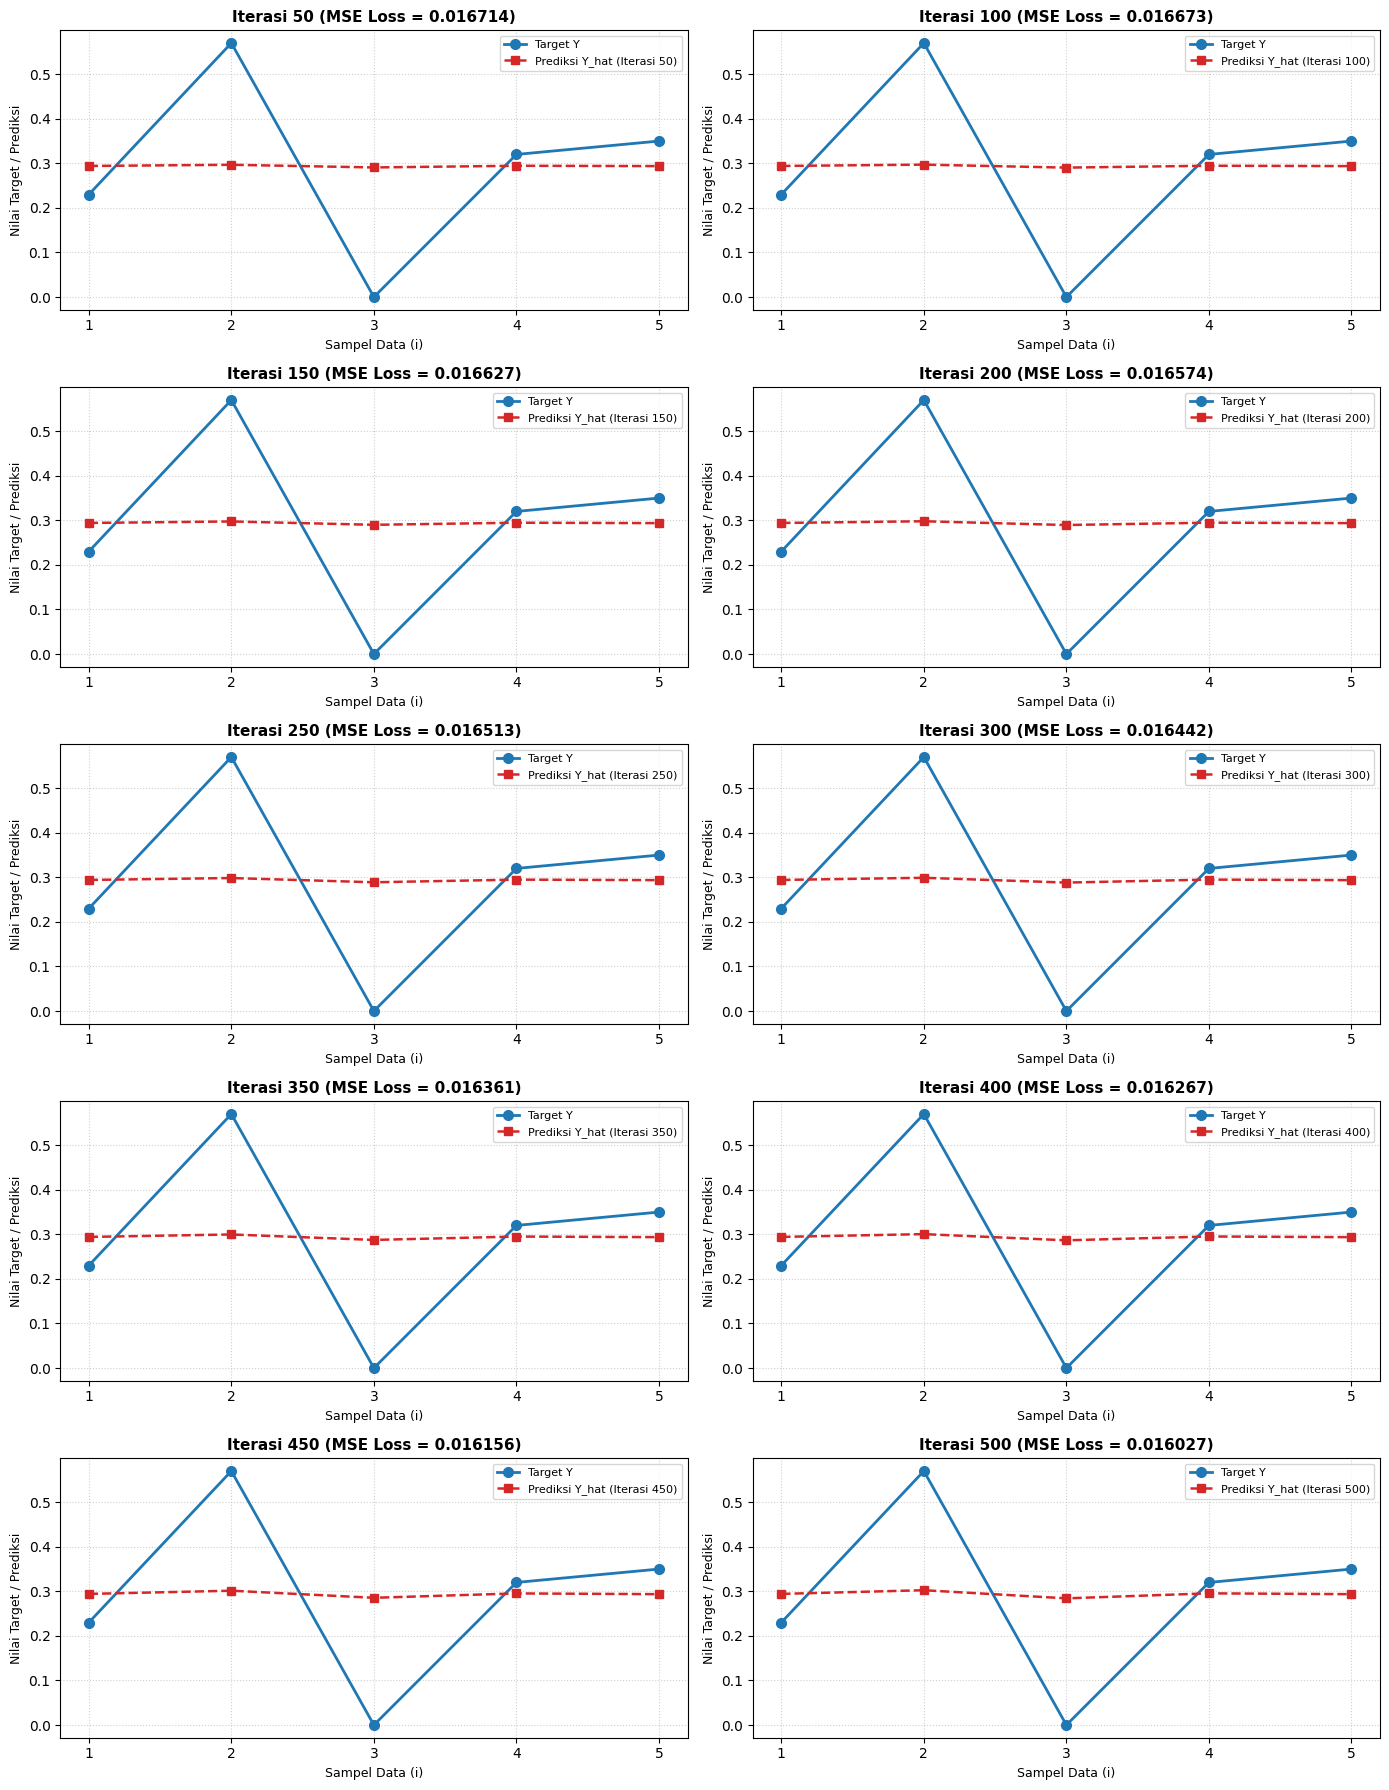

In [3]:
# Visualisasi Perbandingan Target vs Prediksi Setiap Kelipatan 50 Iterasi
plot_epochs = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
samples = np.arange(1, N + 1)

fig, axes = plt.subplots(5, 2, figsize=(14, 18))
axes = axes.flatten()

for idx, ep in enumerate(plot_epochs):
    ax = axes[idx]
    y_pred_ep = predictions_history[ep].ravel()
    loss_ep = history[ep - 1][1]
    
    ax.plot(samples, Y.ravel(), 'o-', color='#1f77b4', linewidth=2, markersize=7, label='Target Y')
    ax.plot(samples, y_pred_ep, 's--', color='#d62728', linewidth=1.8, markersize=6, label=f'Prediksi Y_hat (Iterasi {ep})')
    
    ax.set_title(f'Iterasi {ep} (MSE Loss = {loss_ep:.6f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Sampel Data (i)', fontsize=9)
    ax.set_ylabel('Nilai Target / Prediksi', fontsize=9)
    ax.set_xticks(samples)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()


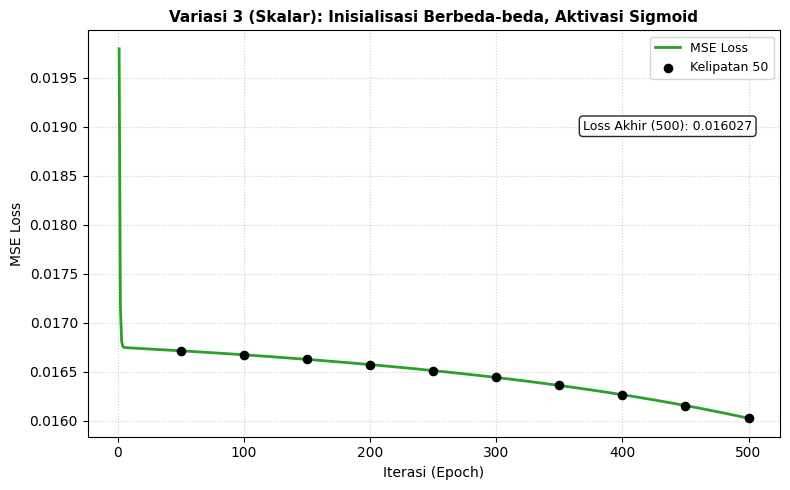

In [4]:
# Visualisasi Grafik Fungsi Loss (MSE Loss vs Iterasi 1 - 500)
epochs = np.array([h[0] for h in history])
losses = np.array([h[1] for h in history])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, losses, color='#2ca02c', linewidth=2, label='MSE Loss')
milestone_epochs = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
milestone_losses = [losses[ep - 1] for ep in milestone_epochs]
ax.scatter(milestone_epochs, milestone_losses, color='black', s=35, zorder=5, label='Kelipatan 50')

ax.set_title("Variasi 3 (Skalar): Inisialisasi Berbeda-beda, Aktivasi Sigmoid", fontsize=11, fontweight='bold')
ax.set_xlabel('Iterasi (Epoch)', fontsize=10)
ax.set_ylabel('MSE Loss', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=9, loc='upper right')
ax.text(0.96, 0.78, f'Loss Akhir (500): {losses[-1]:.6f}', transform=ax.transAxes,
        fontsize=9, ha='right', va='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.show()
